# Plot the Forcing for Spinup, Simulation and Idealized Cases

In [1]:
import sys
sys.path.append('../../')
from utils import plotting_utils
import pickle
import numpy as np
from datetime import timezone


In [2]:
input_folder = "../../input/era5_land_data/Sweden/"
input_folder_idealized = "../../input/idealized/"
filename_spinup = "spinup_2308_2311.pkl"
filename_simulation = "sim_2312_2405.pkl"
filename_idealized = "idealized_forcing.pkl"

In [3]:
def epoch_seconds(dates):
    """naive UTC datetimes (as stored in the ERA5 pickles) -> seconds since 1970-01-01 UTC,
    the time axis plot_forcing_data expects."""
    return np.array([d.replace(tzinfo=timezone.utc).timestamp() for d in dates])

with open(input_folder + filename_spinup, 'rb') as pickle_file:
    db_spinup = pickle.load(pickle_file)
    time_array_spin = epoch_seconds(db_spinup["dates"])
    tl1_array_spin = db_spinup["tl1"]
    recharge_spin = db_spinup["recharge"]

with open(input_folder + filename_simulation, 'rb') as pickle_file:
    db_simulation = pickle.load(pickle_file)
    time_array_sim = epoch_seconds(db_simulation["dates"])
    tl1_array_sim = db_simulation["tl1"]
    recharge_sim = db_simulation["recharge"]

print("spinup:    ", db_spinup["dates"][0], "->", db_spinup["dates"][-1])
print("simulation:", db_simulation["dates"][0], "->", db_simulation["dates"][-1])


spinup:     2023-05-01 00:00:00 -> 2023-10-31 23:00:00
simulation: 2023-11-01 00:00:00 -> 2024-05-31 23:00:00


In [4]:
with open(input_folder_idealized+filename_idealized,'rb') as pickle_file:
    db_ideal = pickle.load(pickle_file)
    time_array_ideal = db_ideal["dates"]
    T_ideal = db_ideal["T_surf"]
    recharge_ideal = db_ideal["recharge"]

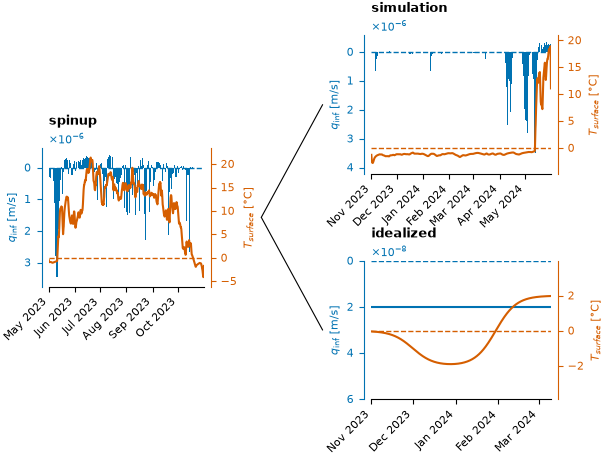

In [5]:
fig, (ax_spin, ax_sim, ax_ideal), axes_cp = plotting_utils.plot_forcing_data_split(
    time_array_spin, time_array_sim, time_array_ideal,
    tl1_array_spin, tl1_array_sim, T_ideal,
    recharge_spin, recharge_sim, recharge_ideal,
)
fig.savefig("../../figures/method/spin_sim_ideal.png",dpi=1000,transparent=True)